In [284]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import *
from sklearn.preprocessing import *
from sklearn.compose import *
from sklearn.metrics import *
import numpy as np
from plotnine import *

In [285]:
ha = pd.read_csv("https://www.dropbox.com/s/aohbr6yb9ifmc8w/heart_attack.csv?dl=1")
ha.head()

,age,sex,cp,trtbps,chol,restecg,thalach,output
0,63,1,3,145,233,0,150,1
1,37,1,2,130,250,1,187,1
2,56,1,1,120,236,1,178,1
3,57,0,0,120,354,1,163,1
4,57,1,0,140,192,1,148,1


In [286]:
ha.isna().sum()

,0
age,0
sex,0
cp,0
trtbps,0
chol,0
restecg,0
thalach,0
output,0


In [287]:
ha.describe()

,age,sex,cp,trtbps,chol,restecg,thalach,output
count,273.000000,273.000000,273.000000,273.000000,273.000000,273.000000,273.000000,273.000000
mean,54.347985,0.673993,0.974359,132.098901,246.860806,0.538462,149.446886,0.534799
std,9.163134,0.469611,1.030456,17.700358,52.569726,0.528059,23.240707,0.499704
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,71.000000,0.000000
25%,47.000000,0.000000,0.000000,120.000000,211.000000,0.000000,133.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.000000,1.000000,152.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.000000,1.000000,166.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,2.000000,202.000000,1.000000


In [288]:
ha.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 273 entries, 0 to 272
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   age      273 non-null    int64
 1   sex      273 non-null    int64
 2   cp       273 non-null    int64
 3   trtbps   273 non-null    int64
 4   chol     273 non-null    int64
 5   restecg  273 non-null    int64
 6   thalach  273 non-null    int64
 7   output   273 non-null    int64
dtypes: int64(8)
memory usage: 17.2 KB


In [289]:
#for plotting purposes to see what is going on:
cat = ['sex', 'cp', 'restecg', 'output']
ha2 = ha.copy()
ha2[cat] = ha2[cat].astype("category")

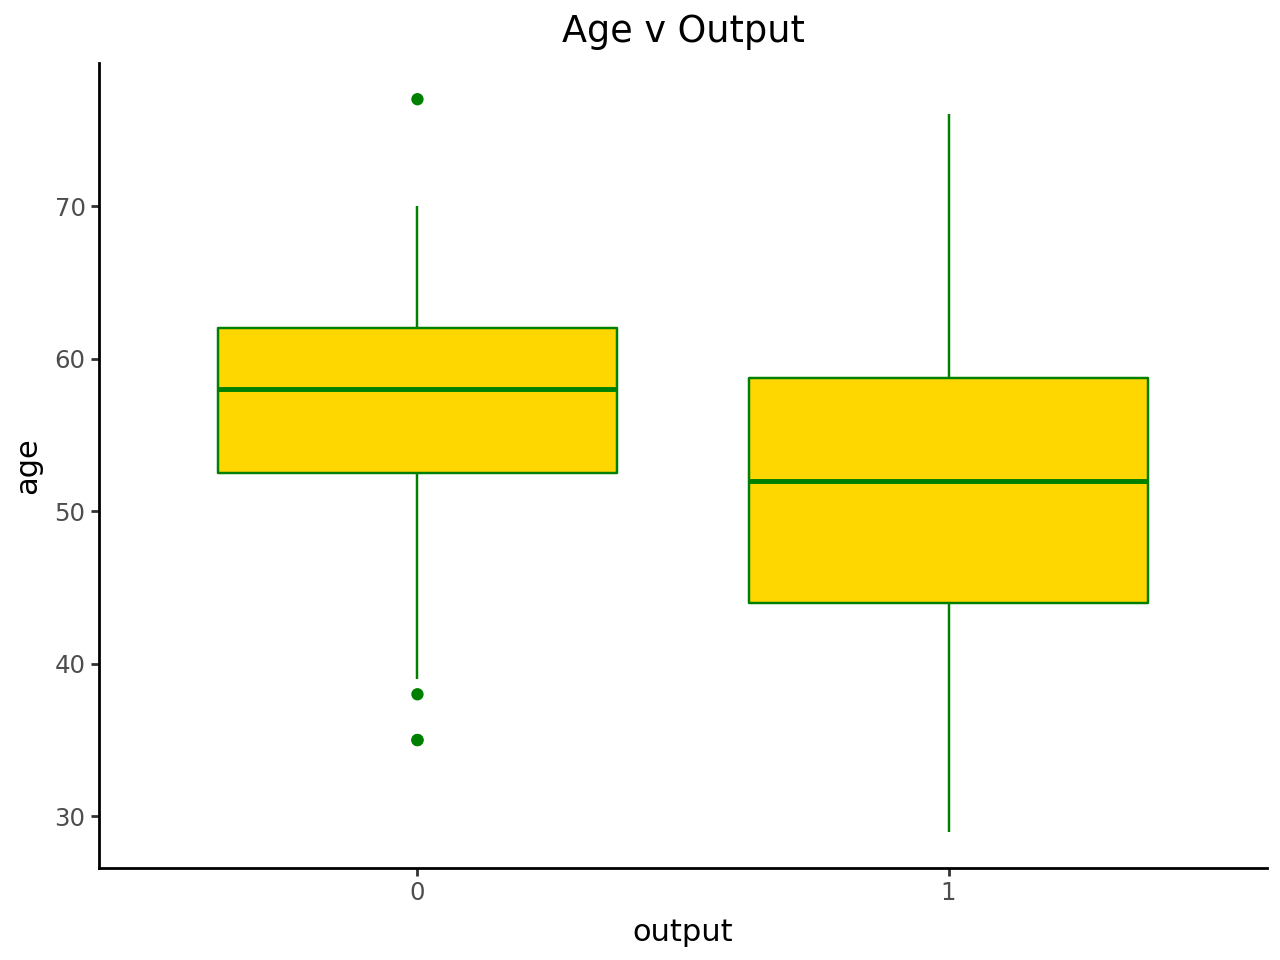

In [290]:
plot1 = (
    ggplot(ha2, aes(x="output", y="age"))
    + geom_boxplot(color="green", fill="gold")
    + labs(title = "Age v Output")
    + theme_classic()
)

plot1

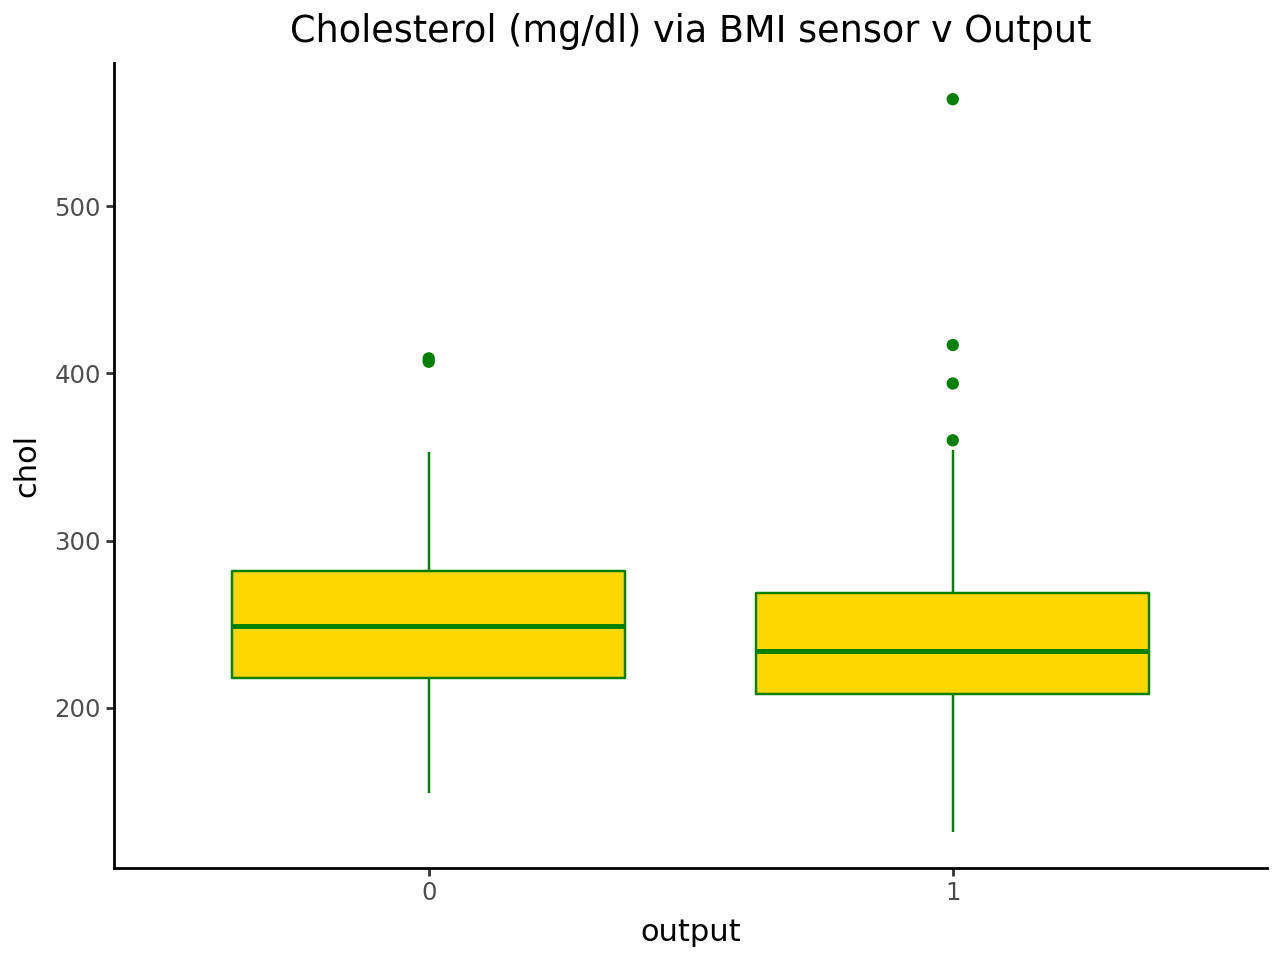

In [291]:
plot2 = (
    ggplot(ha2, aes(x="output", y="chol"))
    + geom_boxplot(color="green", fill="gold")
    + labs(title = "Cholesterol (mg/dl) via BMI sensor v Output")
    + theme_classic()
)

plot2

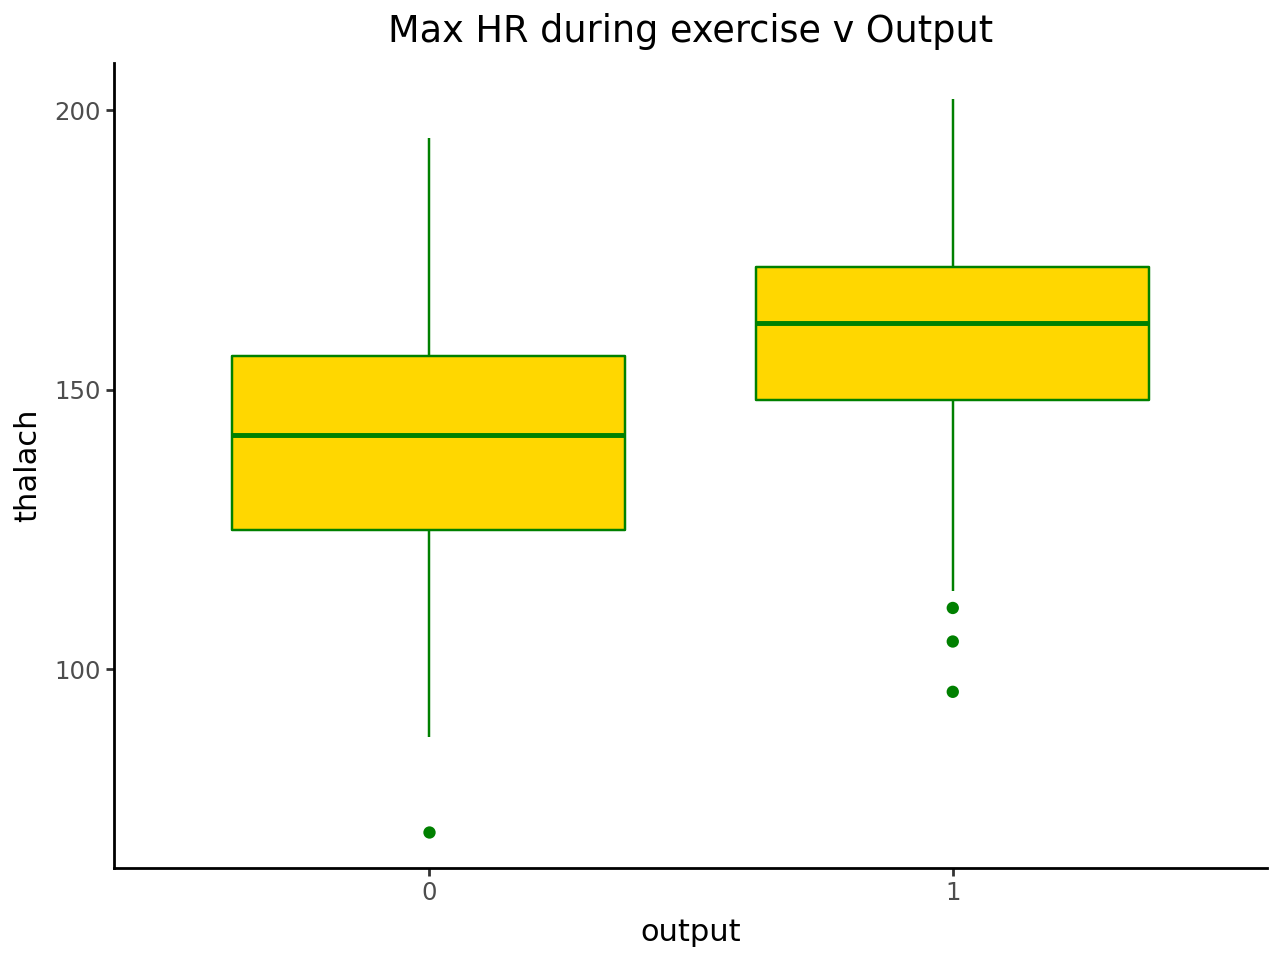

In [292]:
plot3 = (
    ggplot(ha2, aes(x="output", y="thalach"))
    + geom_boxplot(color="green", fill="gold")
    + labs(title = "Max HR during exercise v Output")
    + theme_classic()
)

plot3

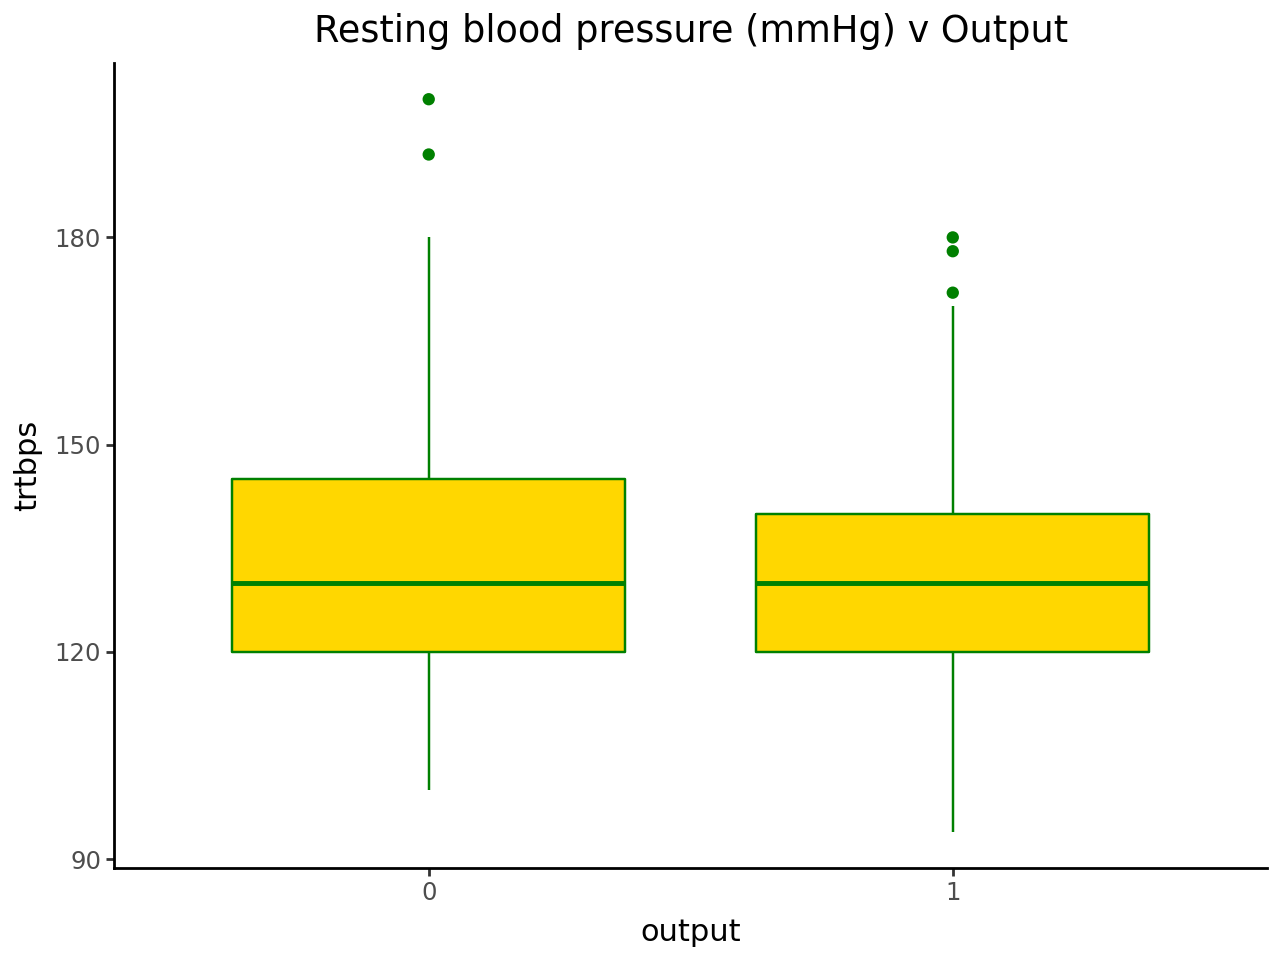

In [293]:
plot4 = (
    ggplot(ha2, aes(x="output", y="trtbps"))
    + geom_boxplot(color="green", fill="gold")
    + labs(title = "Resting blood pressure (mmHg) v Output")
    + theme_classic()
)

plot4

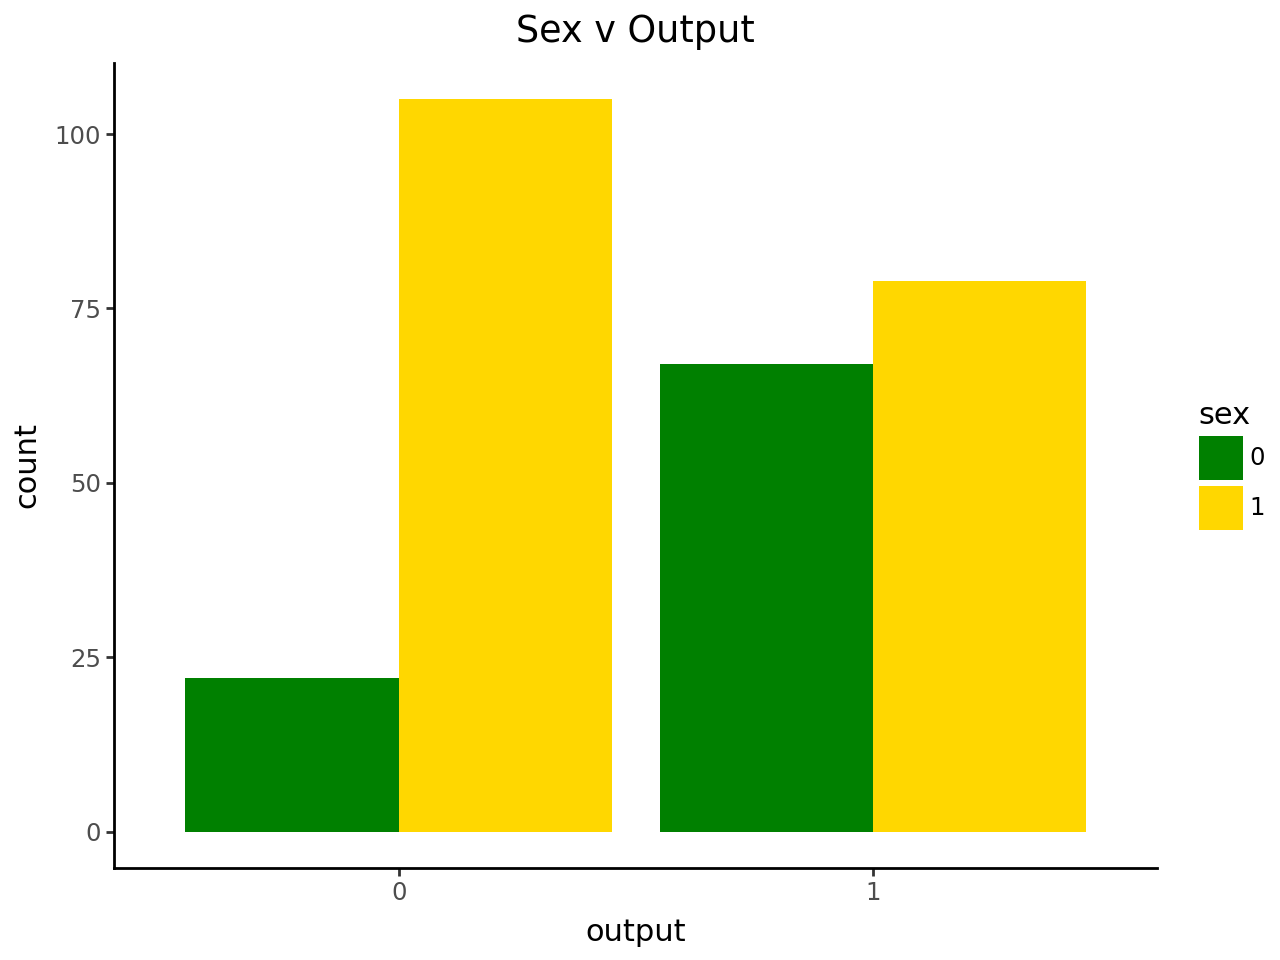

In [294]:
plot5 = (
    ggplot(ha2, aes(x="output"))
    + geom_bar(aes(fill="sex"), position="dodge")
    + scale_fill_manual(values = ["green", "gold"])
    + labs(title = "Sex v Output")
    + theme_classic()
)

plot5

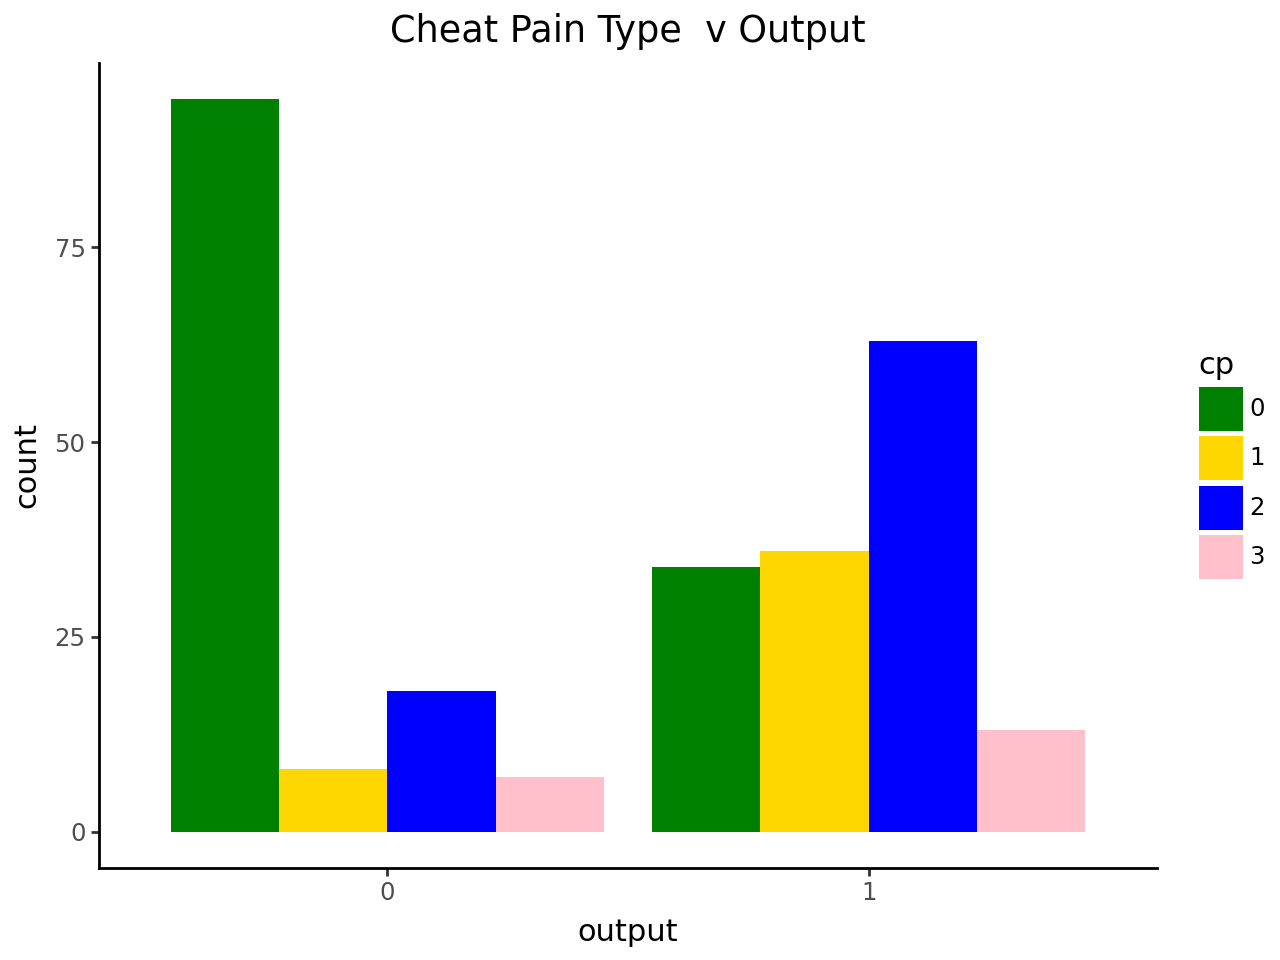

In [295]:
plot6 = (
    ggplot(ha2, aes(x="output"))
    + geom_bar(aes(fill="cp"), position="dodge")
    + scale_fill_manual(values = ["green", "gold", "blue", "pink"])
    + labs(title = "Cheat Pain Type  v Output")
    + theme_classic()
)

plot6

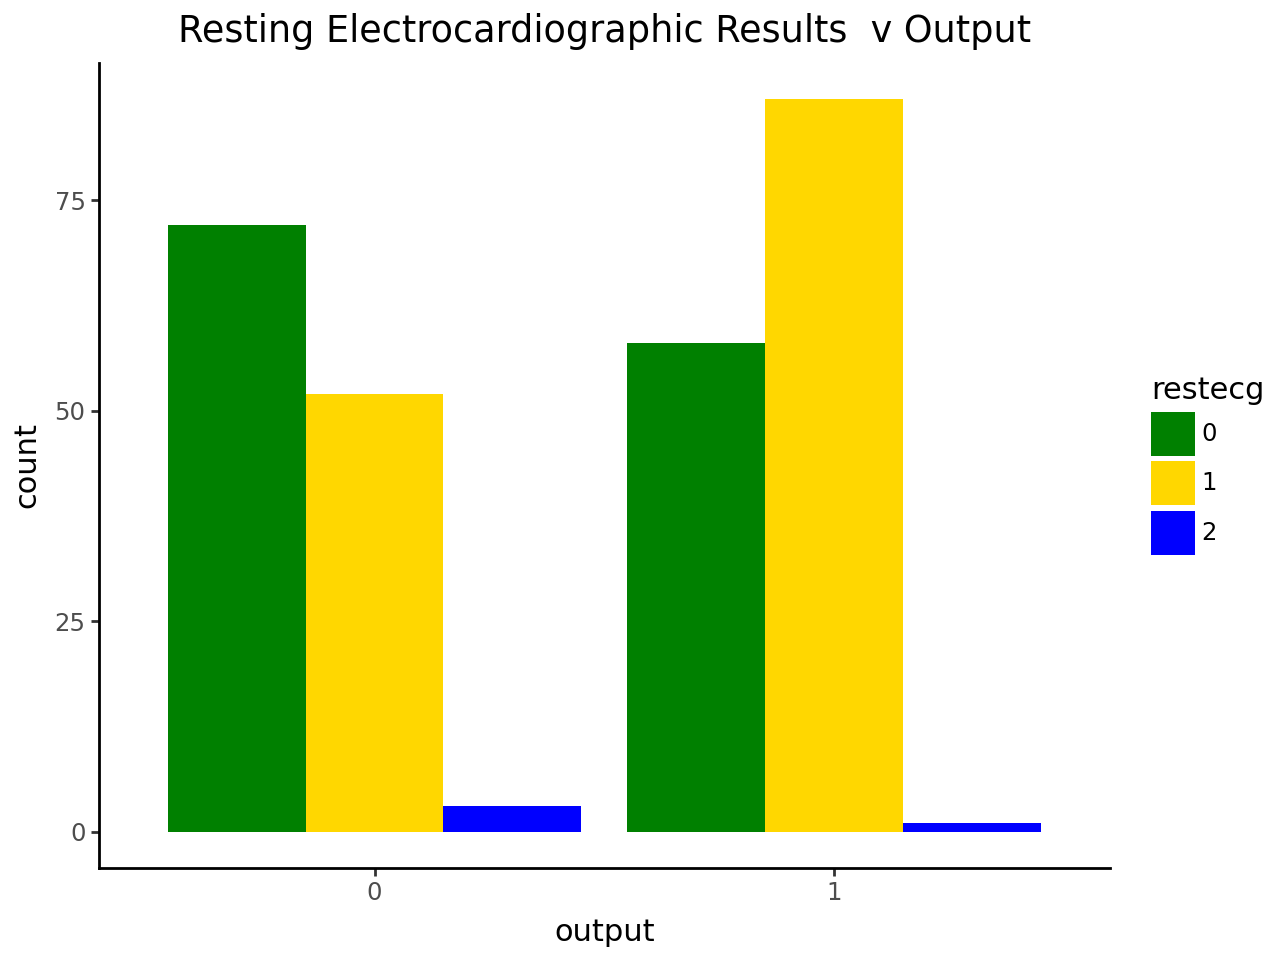

In [296]:
plot7 = (
    ggplot(ha2, aes(x="output"))
    + geom_bar(aes(fill="restecg"), position="dodge")
    + scale_fill_manual(values = ["green", "gold", "blue"])
    + labs(title = "Resting Electrocardiographic Results  v Output")
    + theme_classic()
)

plot7

In [297]:
X = ha.drop(columns="output")
y = ha["output"]

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=321)

In [298]:
cat_var = ["cp", "restecg"]
num_var = ["sex", "chol", "age", "trtbps", "thalach"]


ct = ColumnTransformer(
    [("scalar", StandardScaler(), num_var),
     ("ohe", OneHotEncoder(drop="first", handle_unknown='ignore', sparse_output = False), cat_var)],
    remainder="passthrough"
).set_output(transform="pandas")

scoring = {
    "ACC": "accuracy",
    "PREC": "precision",
    "REC":  "recall",
    "F1": "f1",
    "ROC": "roc_auc",
}

**Part 1 - Fitting Models**

NOTE: All confusion matrices are commented along with the individual series created for the metrics. They are later commented in part 2 with the requested metrics.

**Q1 KNN**

In [300]:
pipe_knn = Pipeline([
    ("ct", ct),
    ("knn", KNeighborsClassifier())
])

In [301]:
paraGrid = {
    'knn__n_neighbors': range(1, 10+1),
    'knn__metric': ['manhattan', 'euclidean']
}
search1 = GridSearchCV(pipe_knn, paraGrid, cv=CV, scoring=scoring, refit="ROC")
KNN_fit = search1.fit(X, y)
pd.DataFrame(KNN_fit.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_knn__metric,param_knn__n_neighbors,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
6,0.010447,0.000398,0.029015,0.002502,manhattan,7,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.709091,0.818182,0.745455,...,0.034217,2,0.802000,0.883952,0.816976,0.813793,0.801379,0.823620,0.030799,1
5,0.011067,0.001000,0.030969,0.005941,manhattan,6,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.690909,0.800000,0.727273,...,0.036714,7,0.800667,0.903183,0.792440,0.791034,0.817241,0.820913,0.042179,2
8,0.010544,0.000348,0.028937,0.001042,manhattan,9,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.745455,0.818182,0.745455,...,0.031494,1,0.792000,0.866711,0.836870,0.808276,0.777931,0.816358,0.031911,3
9,0.011966,0.000442,0.032141,0.001412,manhattan,10,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.672727,0.800000,0.745455,...,0.048419,8,0.768667,0.865385,0.836870,0.797931,0.773793,0.808529,0.037266,4
7,0.011617,0.000432,0.031554,0.002657,manhattan,8,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.690909,0.763636,0.763636,...,0.037617,11,0.772667,0.869363,0.818966,0.806207,0.772414,0.807923,0.035787,5
16,0.010823,0.000815,0.028204,0.001161,euclidean,7,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.690909,0.800000,0.745455,...,0.032325,5,0.750000,0.861406,0.818302,0.791034,0.818621,0.807873,0.036668,6
4,0.010669,0.000336,0.027656,0.000815,manhattan,5,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.672727,0.763636,0.709091,...,0.024230,9,0.761333,0.879973,0.784483,0.791724,0.815172,0.806537,0.040538,7
18,0.011217,0.000678,0.030538,0.001364,euclidean,9,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.672727,0.781818,0.763636,...,0.032356,3,0.739333,0.851459,0.819629,0.806897,0.811724,0.805808,0.036688,8
19,0.012186,0.001813,0.031068,0.004456,euclidean,10,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.690909,0.781818,0.745455,...,0.032260,6,0.730000,0.850796,0.834218,0.798621,0.799310,0.802589,0.041521,9
17,0.010971,0.000626,0.028369,0.001189,euclidean,8,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.690909,0.745455,0.709091,...,0.017882,12,0.727333,0.851459,0.814324,0.800690,0.815862,0.801934,0.040907,10


In [302]:
KNN_fit.best_estimator_.named_steps['knn']

KNeighborsClassifier(metric='manhattan', n_neighbors=7)

In [303]:
knn_best = Pipeline([
    ("ct", ct),
    ("knn", KNeighborsClassifier(n_neighbors=10, metric='manhattan'))

])
knn_best.fit(X, y)

Pipeline(steps=[('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  ['sex', 'chol', 'age',
                                                   'trtbps', 'thalach']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['cp', 'restecg'])])),
                ('knn',
                 KNeighborsClassifier(metric='manhattan', n_neighbors=10))])

In [304]:
cv_knn = cross_validate(knn_best, X, y, scoring=scoring, cv=CV, return_train_score=False)

result_knn = pd.Series({
    "Accuracy": cv_knn["test_ACC"].mean(),
    "Precision": cv_knn["test_PREC"].mean(),
    "Recall": cv_knn["test_REC"].mean(),
    "F1": cv_knn["test_F1"].mean(),
    "ROC_AUC": cv_knn["test_ROC"].mean(),
}, name="KNN Classifier (k=7; euclidean)")

result_knn

,KNN Classifier (k=7; euclidean)
Accuracy,0.736229
Precision,0.793834
Recall,0.685747
F1,0.734038
ROC_AUC,0.808529


In [305]:
y_proba_k = cross_val_predict(knn_best, X, y, cv=CV, method="predict_proba")[:,1]
y_pred_k = (y_proba_k >= 0.5).astype(int)
cm = confusion_matrix(y, y_pred_oof)
cm

array([[ 90,  37],
       [ 30, 116]])

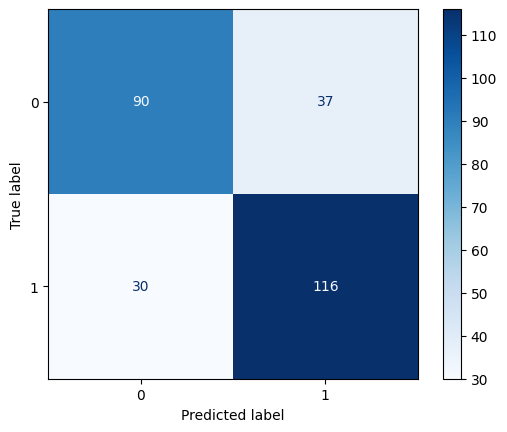

In [306]:
ConfusionMatrixDisplay.from_predictions(y, y_pred_k, cmap = "Blues")

In [307]:
knn_oof = pd.Series({
    "Accuracy": accuracy_score(y, y_pred_oof),
    "Precision": precision_score(y, y_pred_oof),
    "Recall (Sensitivty)": recall_score(y, y_pred_oof),
    "Specificity": recall_score(y, y_pred_oof, pos_label=0),
    "F1": f1_score(y, y_pred_oof),
    "ROC_AUC": roc_auc_score(y, y_proba_oof),
}, name="KNN (OOF)")

knn_oof

,KNN (OOF)
Accuracy,0.754579
Precision,0.758170
Recall (Sensitivty),0.794521
Specificity,0.708661
F1,0.775920
ROC_AUC,0.810430


* Accuracy 75.46%: overall match to true output.

* Precision 75.82%: predicted at risk that are truly output=1.

* Recall 79.45%: truly output=1 predicted at risk.

* Specificity 70.87%: truly output=0 predicted not at risk.

* F1 77.59%: balance of precision & recall for output=1.

* ROC AUC 0.8104: ranks output=1 above output=0 about 81.0% of the time.

NOTE: given that knn classifier does not produce coefficients to interpret as it is non-parametic, such that this approach focuses on storing training points and find the neearest 'nearbors' to make a prediction.

**Q2 Logistic Regression**

In [308]:
pipe_log = Pipeline([
    ("ct", ct),
    ("log", LogisticRegression())
])

In [309]:
logGrid = {"log__C": np.logspace(-3, 3, 13),
           "log__penalty":["l2"],
           "log__solver":["lbfgs","liblinear"],
           "log__max_iter": [1000]}

search2 = GridSearchCV(pipe_log, logGrid, scoring=scoring, cv=CV, refit="ROC")
log_fit = search2.fit(X, y)

In [310]:
log_fit.best_estimator_.named_steps["log"]

LogisticRegression(C=np.float64(10.0), max_iter=1000)

In [311]:
log_best = Pipeline([
    ("ct", ct),
    ("log", LogisticRegression(C=np.float64(10.0), max_iter=1000))
])

log_best.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  ['sex', 'chol', 'age',
                                                   'trtbps', 'thalach']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['cp', 'restecg'])])),
                ('log', LogisticRegression(C=np.float64(10.0), max_iter=1000))])

In [312]:
cv_log = cross_validate(log_best, X, y, scoring=scoring, cv=CV, return_train_score=False)

result_log = pd.Series({
    "Accuracy": cv_log["test_ACC"].mean(),
    "Precision": cv_log["test_PREC"].mean(),
    "Recall": cv_log["test_REC"].mean(),
    "F1": cv_log["test_F1"].mean(),
    "ROC_AUC": cv_log["test_ROC"].mean(),
}, name="Logistic Regression C=np.float64(10.0), max_iter=1000")

result_log

,"Logistic Regression C=np.float64(10.0), max_iter=1000"
Accuracy,0.783771
Precision,0.778973
Recall,0.835172
F1,0.805316
ROC_AUC,0.856325


In [313]:
y_proba_l = cross_val_predict(log_best, X, y, cv=CV, method="predict_proba")[:,1]
y_pred_l= (y_proba_l >= 0.5).astype(int)
cm2 = confusion_matrix(y, y_pred_oof2)
cm2

array([[ 92,  35],
       [ 24, 122]])

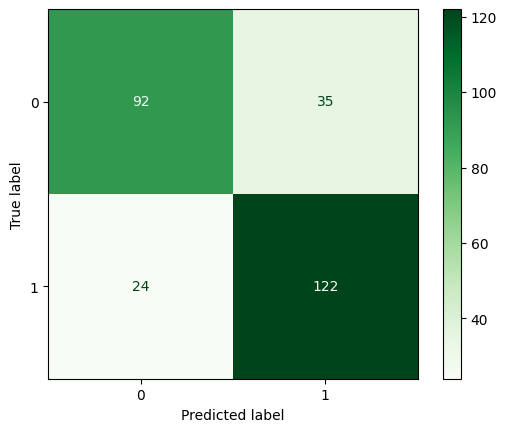

In [314]:
ConfusionMatrixDisplay.from_predictions(y, y_pred_l, cmap = "Greens")

In [316]:
log_oof = pd.Series({
    "Accuracy": accuracy_score(y, y_pred_oof2),
    "Precision": precision_score(y, y_pred_oof2),
    "Recall (Sensitivty)": recall_score(y, y_pred_oof2),
    "Specificity": recall_score(y, y_pred_oof2, pos_label=0),
    "F1": f1_score(y, y_pred_oof2),
    "ROC_AUC": roc_auc_score(y, y_proba_oof2),
}, name="Log (OOF)")

log_oof

,Log (OOF)
Accuracy,0.783883
Precision,0.777070
Recall (Sensitivty),0.835616
Specificity,0.724409
F1,0.805281
ROC_AUC,0.858645


* Accuracy 78.39%: of all patients, predictions match the true output.

* Precision 77.71%: among patients predicted at risk, truly output=1.

* Recall 83.56%: among patients truly at risk (output=1), predicted at risk.

* Specificity 72.44%: among patients truly not at risk (output=0), predicted not at risk.

* F1 80.53%: single score balancing precision & recall for output=1.

* ROC AUC 0.8586: probability the model scores an at-risk (output=1) patient higher than a not-at-risk (output=0) patient.

**Q3 Decision Tree**

In [317]:
pipe_dt = Pipeline([
    ("ct", ct),
    ("dt", DecisionTreeClassifier())
])

In [318]:
dtGrid = {
    "dt__max_depth": [None, 3, 5, 10, 20],
    "dt__min_samples_leaf": [1, 2, 5],
    "dt__max_features": [None, "sqrt", "log2"],
    "dt__ccp_alpha": [0.0, 1e-3, 1e-2],
}

search3 = GridSearchCV(pipe_dt, dtGrid, scoring=scoring, cv=CV, refit="ROC")
dt_fit = search3.fit(X, y)

In [319]:
dt_fit.best_estimator_.named_steps["dt"]

DecisionTreeClassifier(ccp_alpha=0.001, max_depth=5, max_features='sqrt',
                       min_samples_leaf=2)

In [320]:
dt_best = Pipeline([
    ("ct", ct),
    ("dt", DecisionTreeClassifier(ccp_alpha=0.001, max_depth=5, min_samples_leaf=2, max_features="sqrt"))
])

dt_best.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  ['sex', 'chol', 'age',
                                                   'trtbps', 'thalach']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['cp', 'restecg'])])),
                ('dt',
                 DecisionTreeClassifier(ccp_alpha=0.001, max_depth=5,
                                        max_features='sqrt',
                                        min_samples_leaf=2))])

In [321]:
cv_dt = cross_validate(dt_best, X, y, scoring=scoring, cv=CV, return_train_score=False)

result_dt = pd.Series({
    "Accuracy": cv_dt["test_ACC"].mean(),
    "Precision": cv_dt["test_PREC"].mean(),
    "Recall": cv_dt["test_REC"].mean(),
    "F1": cv_dt["test_F1"].mean(),
    "ROC_AUC": cv_dt["test_ROC"].mean(),
}, name="Logistic Regression C=np.float64(10.0), max_iter=1000")

result_dt

,"Logistic Regression C=np.float64(10.0), max_iter=1000"
Accuracy,0.699394
Precision,0.762826
Recall,0.649655
F1,0.696519
ROC_AUC,0.747315


In [322]:
y_proba_dt = cross_val_predict(dt_best, X, y, cv=CV, method="predict_proba")[:,1]
y_pred_dt = (y_proba_dt >= 0.5).astype(int)
cm3 = confusion_matrix(y, y_pred_dt)
cm3

array([[ 81,  46],
       [ 46, 100]])

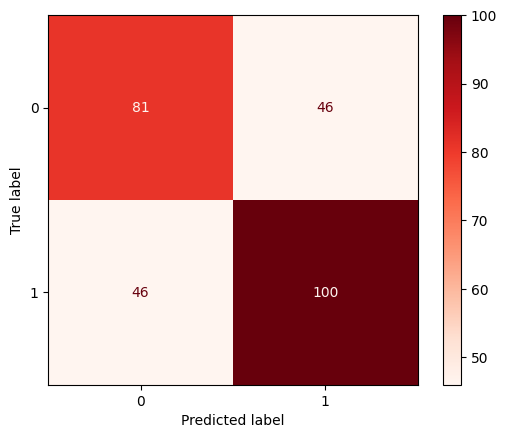

In [323]:
ConfusionMatrixDisplay.from_predictions(y, y_pred_dt, cmap = "Reds")

In [324]:
dt_oof = pd.Series({
    "Accuracy": accuracy_score(y, y_pred_oof3),
    "Precision": precision_score(y, y_pred_oof3),
    "Recall (Sensitivty)": recall_score(y, y_pred_oof3),
    "Specificity":  recall_score(y, y_pred_oof3, pos_label=0),
    "F1": f1_score(y, y_pred_oof3),
    "ROC_AUC": roc_auc_score(y, y_proba_oof3),
}, name="DT (OOF)")

dt_oof

,DT (OOF)
Accuracy,0.655678
Precision,0.688406
Recall (Sensitivty),0.650685
Specificity,0.661417
F1,0.669014
ROC_AUC,0.711034


* Accuracy 64.10%: overall match to true output.

* Precision 68.42%: predicted at risk that are truly output=1.

* Recall 62.33%: truly output=1 predicted at risk.

* Specificity 66.93%: truly output=0 predicted not at risk.

* F1 65.00%: balance of precision & recall for output=1.

* ROC AUC 0.6979: ranks output=1 above output=0 about 70.7% of the time.

**Q4 Interpretations - Log & DT**

In [325]:
lr_coef_df = pd.DataFrame({
    "Variable": log_best.named_steps["ct"].get_feature_names_out(),
    "Coef": log_best.named_steps['log'].coef_.flatten()})

lr_coef_df.sort_values(by='Coef', key=lambda s: np.abs(s), ascending=False)

,Variable,Coef
5,ohe__cp_1,2.169681
6,ohe__cp_2,1.983998
7,ohe__cp_3,1.846550
0,scalar__sex,-1.034098
4,scalar__thalach,0.795294
9,ohe__restecg_2,-0.627733
3,scalar__trtbps,-0.345249
8,ohe__restecg_1,0.338104
1,scalar__chol,-0.308445
2,scalar__age,-0.239247


In [326]:
tree_import_df = pd.DataFrame({
    "Variable": dt_best.named_steps['ct'].get_feature_names_out(),
    "Tree Importance": dt_best.named_steps['dt'].feature_importances_
})

tree_import_df.sort_values(by="Tree Importance", ascending=False)

,Variable,Tree Importance
6,ohe__cp_2,0.229193
4,scalar__thalach,0.172767
5,ohe__cp_1,0.159114
2,scalar__age,0.152840
0,scalar__sex,0.113283
1,scalar__chol,0.112351
7,ohe__cp_3,0.037544
3,scalar__trtbps,0.022907
8,ohe__restecg_1,0.000000
9,ohe__restecg_2,0.000000


In [354]:
#Coeffs listed by importance via DT Classifier with the coefficient of Logistic Regression

import_var = pd.merge(lr_coef_df, tree_import_df, on="Variable")
import_var = import_var.sort_values("Tree Importance", ascending=False)
import_var["odds"] = np.exp(import_var["Coef"])
import_var

,Variable,Coef,Tree Importance,odds
6,ohe__cp_2,1.983998,0.229193,7.271759
4,scalar__thalach,0.795294,0.172767,2.215093
5,ohe__cp_1,2.169681,0.159114,8.755489
2,scalar__age,-0.239247,0.152840,0.787220
0,scalar__sex,-1.034098,0.113283,0.355547
1,scalar__chol,-0.308445,0.112351,0.734588
7,ohe__cp_3,1.846550,0.037544,6.337918
3,scalar__trtbps,-0.345249,0.022907,0.708044
8,ohe__restecg_1,0.338104,0.000000,1.402286
9,ohe__restecg_2,-0.627733,0.000000,0.533801


**Interpretations (top 5)**

Based in the importance from the DT, we can see that some of the variables that stood out were atypical angina (cp2), thalach, typical angina (cp1), age, and sex.   


1.   **cp2**: All else constant, a person with atypical angina is 7.3 times as likely to be at risk of a heart attack than a person that is asymptomatic.

1.   **Thalach**: All else constant, for each increase in 1 standard deviation for maximum heart rate acheived during exercise, a person is 2.21 times more likely to be at risk of a heart attack.

2.   **cp1**: All else constant, a person with typical angina is 8.775 times as likely to be at risk of a heart attack than a person that is asymptomatic.

2.   **age**:  All else constant, for each increase in 1 standard deviation for age, a person is 0.79 times more likely to be at risk of a heart attack.

2.   **sex**: All else constant, a male 0.36 times as likely to be at risk of a heart attack than a female.



**Q5 ROC Curve**

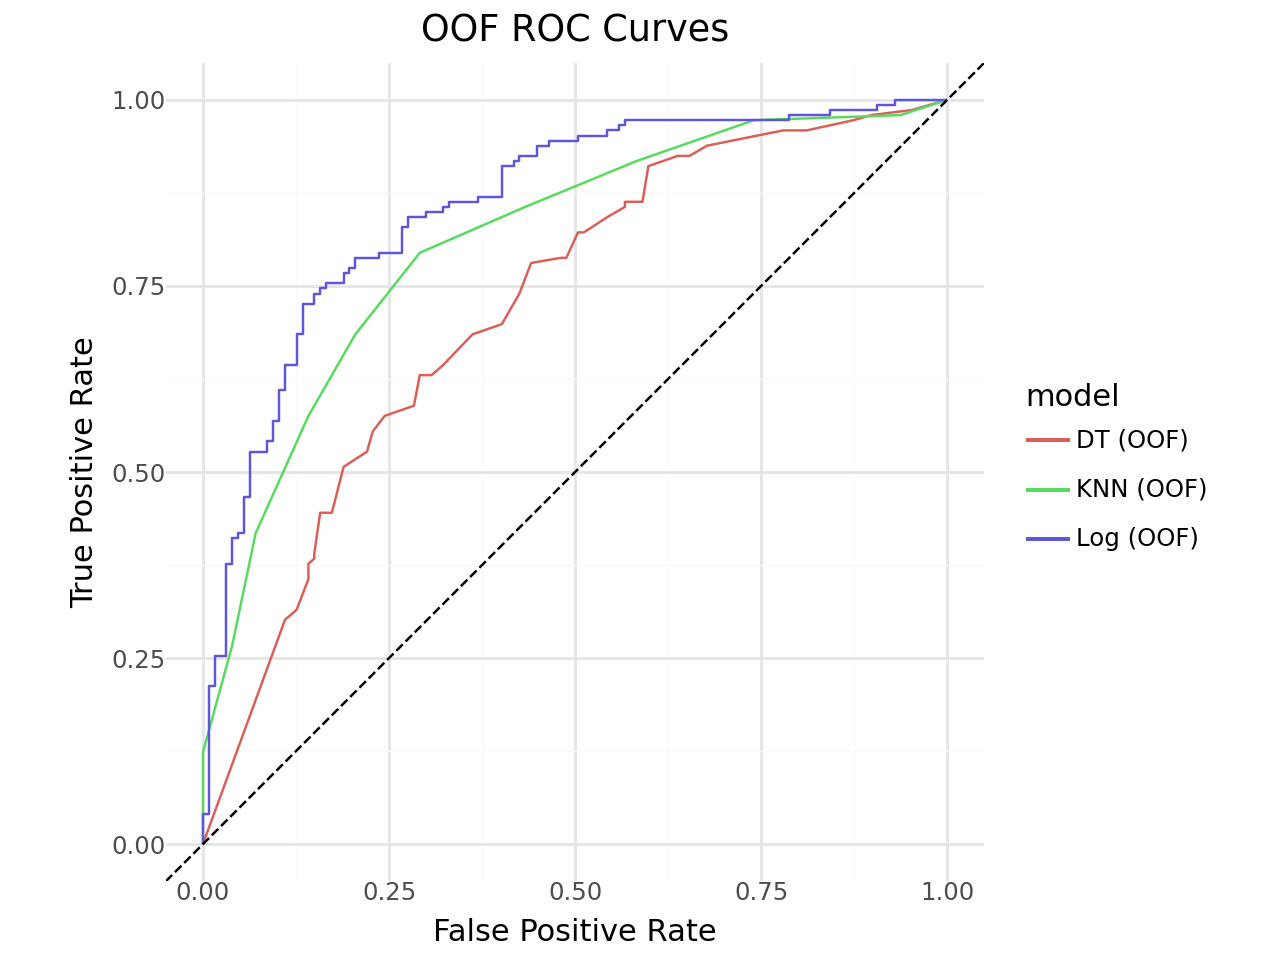

In [348]:
fpr_knn, tpr_knn, _ = roc_curve(y, y_proba_k)
df_knn = pd.DataFrame({"model": "KNN (OOF)", "FPR": fpr_knn, "TPR": tpr_knn})

fpr_log, tpr_log, _ = roc_curve(y, y_proba_l)
df_log = pd.DataFrame({"model": "Log (OOF)", "FPR": fpr_log, "TPR": tpr_log})

fpr_dt, tpr_dt, _ = roc_curve(y, y_proba_dt)
df_dt = pd.DataFrame({"model": "DT (OOF)", "FPR": fpr_dt, "TPR": tpr_dt})

roc_curve_df = pd.concat([df_log, df_knn, df_dt], ignore_index=True)

(ggplot(roc_curve_df, aes("FPR", "TPR", color="model"))
 + geom_path()
 + geom_abline(linetype="dashed")
 + coord_equal()
 + labs(title="OOF ROC Curves", x="False Positive Rate", y="True Positive Rate")
 + theme_minimal())

From these ROC curves, it looks like that Logistic Regression performs the best such that it had the highest score (can be seen in part 2 with the total metrics) it best predicts cases higher cases for true positives over true negatives.

#**Part 2: Metrics**

In [329]:
table = pd.concat([knn_oof, log_oof, dt_oof], axis=1).T
table.sort_values(by='ROC_AUC', ascending=False).style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall (Sensitivty)": "{:.4f}", "Specificity": "{:.4f}", "F1": "{:.4f}", "ROC_AUC": "{:.4f}"})

,Accuracy,Precision,Recall (Sensitivty),Specificity,F1,ROC_AUC
Log (OOF),0.7839,0.7771,0.8356,0.7244,0.8053,0.8586
KNN (OOF),0.7546,0.7582,0.7945,0.7087,0.7759,0.8104
DT (OOF),0.6557,0.6884,0.6507,0.6614,0.6690,0.7110


RECALL FROM PART 1

**KNN (OOF)**

*   Recall: among patients truly output=1, 79.5% are predicted at risk.

*   Precision: among patients predicted at risk, 75.8% are truly output=1.

*   Specificity: among patients truly output=0, 70.9% are predicted not at risk.

**Logistic (OOF)**

*   Recall (Sensitivity/TPR): among patients truly at risk(output=1), 83.6% are predicted at risk.

*   Precision (PPV): among patients predicted at risk, 77.7% are truly output=1.

*   Specificity (TNR): among patients truly not at risk (output=0), 72.4% are predicted not at risk.

**Decision Tree (OOF)**

*   Recall: among patients truly output=1, 62.3% are predicted at risk.
*   Precision: among patients predicted at risk, 68.4% are truly output=1.

*  Specificity: among patients truly output=0, 66.9% are predicted not at risk

#**Part 3: Discussion**

Each scenario answers the following set of questions:

*   The metric that I would select for model selection would be

*   The model from part 1 that I would select for the hospital would be

*   The score that I have chosen from the preferred model to predict future observations would be



Q1: The hospital faces severe lawsuits if they deem a patient to be low risk, and that patient later experiences a heart attack.

* Metric(s): Recall to avoid missing at-risk patients and avoid a dire situation; ROC score to confirm the model consistently ranks at-risk above not-at-risk across score cutoffs.

* Model: Logistic — highest recall 0.8356 and strongest ranking signal ROC score 0.8586 on your data.

* Score used: Recall ≈ 0.836 — aligns with the hospital’s priority to minimize missed heart-attack risk.

Q2: The hospital is overfull, and wants to only use bed space for patients most in need of monitoring due to heart attack risk.

* metric(s): Precision to ensure admitted patients truly are at risk and; Specificity to avoid admitting not-at-risk patients, which both focus on utilizing hosputal space efficeintly.

Model: Logistic — best precision 0.7771 and solid specificity 0.7244; Decision Tree may be chosen when simple, transparent bedside rules are needed for triage, despite lower performance.

Score used: Precision ≈ 0.777 — aligns with conserving beds for those most likely at risk.

Q3: The hospital is studying root causes of heart attacks, and would like to understand which biological measures are associated with heart attack risk.

* Metric(s): Roc score for reliable separation, plus coefficients for understanding which biological measures associate with risk.

* Model: Logistic — provides interpretable coefficients (e.g., for age, chest-pain type, heart rate) and strong separation (Roc score 0.8586).

* Score used: Roc score ≈ 0.86 — clear, threshold-independent summary for research reporting.

Q4: The hospital is training a new batch of doctors, and they would like to compare the diagnoses of these doctors to the predictions given by the algorithm to measure the ability of new doctors to diagnose patients.

* Metric(s): Roc score to compare doctors and the algorithm fairly across thresholds; Accuracy to check simple agreement.

* Model: Logistic — top Roc score 0.8586 and highest accuracy 0.7839; Decision Tree may be used when you need explainable, rule-based comparisons to teach trainees how specific variable thresholds map to decisions.

* Score used: Roc score ≈ 0.86 — stable benchmark for evaluating new doctors against the model.

#**Part 4**

In [330]:
ha_validation = pd.read_csv("https://www.dropbox.com/s/jkwqdiyx6o6oad0/heart_attack_validation.csv?dl=1")
ha_validation.head()

,age,sex,cp,trtbps,chol,restecg,thalach,output
0,41,0,1,130,204,0,172,1
1,64,1,3,110,211,0,144,1
2,59,1,0,135,234,1,161,1
3,42,1,0,140,226,1,178,1
4,40,1,3,140,199,1,178,1


In [331]:
ha_validation.isna().sum()

,0
age,0
sex,0
cp,0
trtbps,0
chol,0
restecg,0
thalach,0
output,0


In [332]:
ha_validation.describe()

,age,sex,cp,trtbps,chol,restecg,thalach,output
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,54.533333,0.766667,0.900000,127.300000,240.833333,0.433333,151.466667,0.633333
std,8.451620,0.430183,1.061879,15.592107,44.962117,0.504007,19.842020,0.490133
min,40.000000,0.000000,0.000000,100.000000,131.000000,0.000000,111.000000,0.000000
25%,48.000000,1.000000,0.000000,113.500000,205.750000,0.000000,143.250000,0.000000
50%,54.500000,1.000000,0.500000,130.000000,245.000000,0.000000,155.000000,1.000000
75%,59.000000,1.000000,2.000000,139.500000,272.500000,1.000000,162.000000,1.000000
max,71.000000,1.000000,3.000000,160.000000,330.000000,1.000000,182.000000,1.000000


In [333]:
ha_validation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   age      30 non-null     int64
 1   sex      30 non-null     int64
 2   cp       30 non-null     int64
 3   trtbps   30 non-null     int64
 4   chol     30 non-null     int64
 5   restecg  30 non-null     int64
 6   thalach  30 non-null     int64
 7   output   30 non-null     int64
dtypes: int64(8)
memory usage: 2.0 KB


In [334]:
#We are fitting on our best models such that they meet the same parameters derived from earlier and fit this model

X2 = ha_validation.drop(columns="output")
y2 = ha_validation["output"]

In [335]:
knn_best2 = Pipeline([
    ("ct", ct),
    ("knn", KNeighborsClassifier(n_neighbors=10, metric='manhattan'))

])
knn_best2.fit(X, y)

Pipeline(steps=[('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  ['sex', 'chol', 'age',
                                                   'trtbps', 'thalach']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['cp', 'restecg'])])),
                ('knn',
                 KNeighborsClassifier(metric='manhattan', n_neighbors=10))])

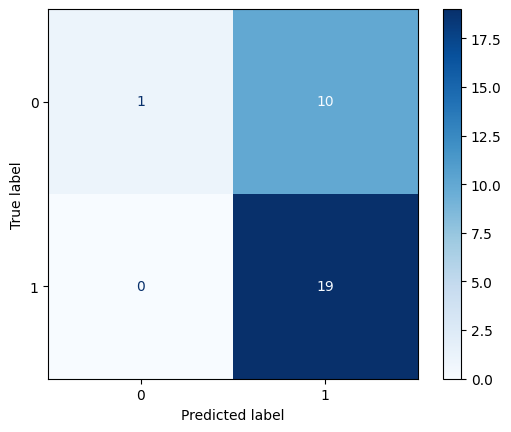

In [337]:
y_proba_k2 = cross_val_predict(knn_best2, X2, y2, cv=CV, method="predict_proba")[:,1]
y_pred_k2 = (y_proba_k2 >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y2, y_pred_k2, cmap = "Blues")

In [338]:
knn_oof2 = pd.Series({
    "Accuracy": accuracy_score(y2, y_pred_k2),
    "Precision": precision_score(y2, y_pred_k2),
    "Recall (Sensitivty)": recall_score(y2, y_pred_k2),
    "Specificity": recall_score(y2, y_pred_k2, pos_label=0),
    "F1": f1_score(y2, y_pred_k2),
    "ROC_AUC": roc_auc_score(y2, y_proba_k2),
}, name="KNN #2 (OOF)")

knn_oof2

,KNN #2 (OOF)
Accuracy,0.666667
Precision,0.655172
Recall (Sensitivty),1.000000
Specificity,0.090909
F1,0.791667
ROC_AUC,0.708134


In [339]:
log_best2 = Pipeline([
    ("ct", ct),
    ("log", LogisticRegression(C=np.float64(10.0), max_iter=1000))
])

log_best2.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  ['sex', 'chol', 'age',
                                                   'trtbps', 'thalach']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['cp', 'restecg'])])),
                ('log', LogisticRegression(C=np.float64(10.0), max_iter=1000))])

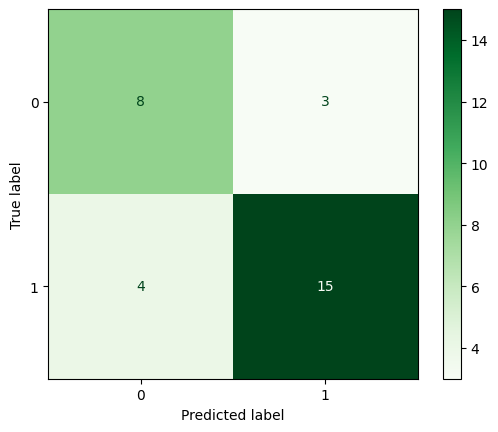

In [340]:
y_proba_l2 = cross_val_predict(log_best2, X2, y2, cv=CV, method="predict_proba")[:,1]
y_pred_l2 = (y_proba_oofl2 >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y2, y_pred_l2, cmap = "Greens")

In [341]:
log_oof2 = pd.Series({
    "Accuracy": accuracy_score(y2, y_pred_l2),
    "Precision": precision_score(y2, y_pred_l2),
    "Recall (Sensitivty)": recall_score(y2, y_pred_l2),
    "Specificity": recall_score(y2, y_pred_l2, pos_label=0),
    "F1": f1_score(y2, y_pred_l2),
    "ROC_AUC": roc_auc_score(y2, y_proba_l2),
}, name="Log #2 (OOF)")

log_oof2

,Log #2 (OOF)
Accuracy,0.766667
Precision,0.833333
Recall (Sensitivty),0.789474
Specificity,0.727273
F1,0.810811
ROC_AUC,0.794258


In [343]:
dt_best2 = Pipeline([
    ("ct", ct),
    ("dt", DecisionTreeClassifier(ccp_alpha=0.001, max_depth=5, min_samples_leaf=2, max_features="sqrt"))
])

dt_best2.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('scalar', StandardScaler(),
                                                  ['sex', 'chol', 'age',
                                                   'trtbps', 'thalach']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['cp', 'restecg'])])),
                ('dt',
                 DecisionTreeClassifier(ccp_alpha=0.001, max_depth=5,
                                        max_features='sqrt',
                                        min_samples_leaf=2))])

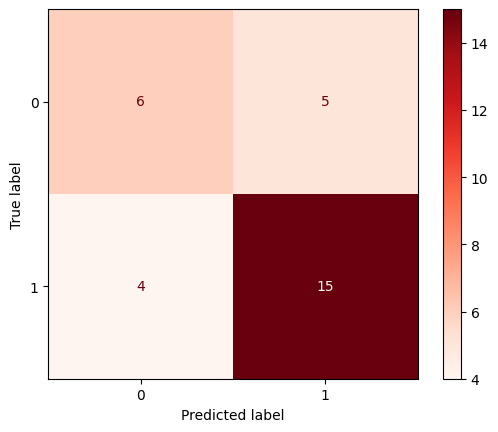

In [344]:
y_proba_dt2 = cross_val_predict(dt_best2, X2, y2, cv=CV, method="predict_proba")[:,1]
y_pred_dt2 = (y_proba_dt2 >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y2, y_pred_dt2, cmap = "Reds")

In [345]:
dt_oof2 = pd.Series({
    "Accuracy": accuracy_score(y2, y_pred_dt2),
    "Precision": precision_score(y2, y_pred_dt2),
    "Recall (Sensitivty)": recall_score(y2, y_pred_dt2),
    "Specificity": recall_score(y2, y_pred_dt2, pos_label=0),
    "F1": f1_score(y2, y_pred_dt2),
    "ROC_AUC": roc_auc_score(y2, y_proba_dt2),
}, name="DT #2 (OOF)")

dt_oof2

,DT #2 (OOF)
Accuracy,0.700000
Precision,0.750000
Recall (Sensitivty),0.789474
Specificity,0.545455
F1,0.769231
ROC_AUC,0.705742


In [346]:
table2 = pd.concat([knn_oof2, log_oof2, dt_oof2], axis=1).T
table2.sort_values(by='ROC_AUC', ascending=False).style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall (Sensitivty)": "{:.4f}", "Specificity": "{:.4f}", "F1": "{:.4f}", "ROC_AUC": "{:.4f}"})

,Accuracy,Precision,Recall (Sensitivty),Specificity,F1,ROC_AUC
Log #2 (OOF),0.7667,0.8333,0.7895,0.7273,0.8108,0.7943
KNN #2 (OOF),0.6667,0.6552,1.0000,0.0909,0.7917,0.7081
DT #2 (OOF),0.7000,0.7500,0.7895,0.5455,0.7692,0.7057


In [347]:
combined_table = pd.concat([table, table2], axis=0)
combined_table.sort_values(by='ROC_AUC', ascending=False).style.format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall (Sensitivty)": "{:.4f}", "Specificity": "{:.4f}", "F1": "{:.4f}", "ROC_AUC": "{:.4f}"})

,Accuracy,Precision,Recall (Sensitivty),Specificity,F1,ROC_AUC
Log (OOF),0.7839,0.7771,0.8356,0.7244,0.8053,0.8586
KNN (OOF),0.7546,0.7582,0.7945,0.7087,0.7759,0.8104
Log #2 (OOF),0.7667,0.8333,0.7895,0.7273,0.8108,0.7943
DT (OOF),0.6557,0.6884,0.6507,0.6614,0.6690,0.7110
KNN #2 (OOF),0.6667,0.6552,1.0000,0.0909,0.7917,0.7081
DT #2 (OOF),0.7000,0.7500,0.7895,0.5455,0.7692,0.7057


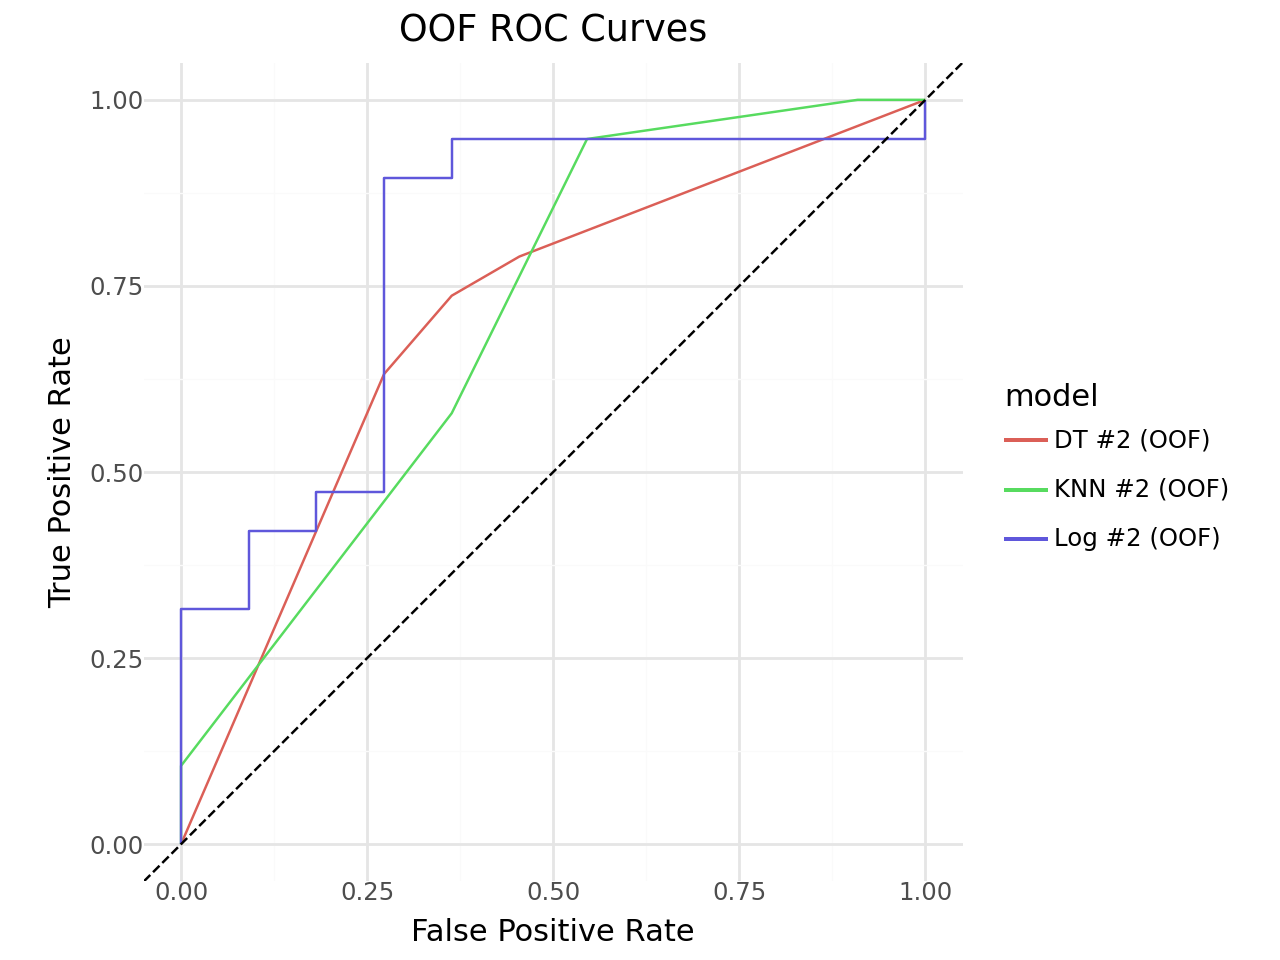

In [350]:
fpr_knn2, tpr_knn2, _ = roc_curve(y2, y_proba_k2)
df_knn2 = pd.DataFrame({"model": "KNN #2 (OOF)", "FPR": fpr_knn2, "TPR": tpr_knn2})

fpr_log2, tpr_log2, _ = roc_curve(y2, y_proba_l2)
df_log2 = pd.DataFrame({"model": "Log #2 (OOF)", "FPR": fpr_log2, "TPR": tpr_log2})

fpr_dt2, tpr_dt2, _ = roc_curve(y2, y_proba_dt2)
df_dt2 = pd.DataFrame({"model": "DT #2 (OOF)", "FPR": fpr_dt2, "TPR": tpr_dt2})

roc_curve_df = pd.concat([df_log2, df_knn2, df_dt2], ignore_index=True)

(ggplot(roc_curve_df, aes("FPR", "TPR", color="model"))
 + geom_path()
 + geom_abline(linetype="dashed")
 + coord_equal()
 + labs(title="OOF ROC Curves", x="False Positive Rate", y="True Positive Rate")
 + theme_minimal())

For some models, they tested in better areas in the validation set based on the best model from part 1 and 2. In this concatenated table with all the metrics, we can see tat KNN actually had a 100% Recall, which means is a little bizarre as it did not seem like an ideal model with just the training data. However, the roc value is much lower which may indicate the ranking system system is moderate. The Decision Tree in this instance performed the worst, but had some similiarities to the models from part 1 such that the accuracy and ROC were similar. For the most part, the logistic regression did the best out of these 3 with the validation set given only the sensitivity and ROC had subtle changes.

#**Part 5**

In [353]:
from sklearn.metrics import cohen_kappa_score

kappa_dt = cohen_kappa_score(y, y_pred_dt)
kappa_log = cohen_kappa_score(y, y_pred_l)
kappa_knn = cohen_kappa_score(y, y_pred_k)

print(f"Kappa DT: {kappa_dt :4f}")
print(f"Kappa Log: {kappa_log :4f}")
print(f"Kappa KNN: {kappa_knn :4f}")

Kappa DT: 0.322727
Kappa Log: 0.563200
Kappa KNN: 0.504993


Conclusion: In spite of modeling, some models may not perform as well in the validation set as it may have been perceived in the trainingset. For instance, we saw this take place when fitting the datting and then testing it with the validation set that many values varied largely and this could be an issue possibly with accuracy or some other imbalanced metric. The inconsistencies within the validation and training data suggest there's an imbalance.

Cohen's Kappa penalizaes chance agreement so the models may not just be favorable based on the predicting capabilities and account for imbalances that may present themselves when comparing the training and test data. It may be a result on data not partitioning correctly such that majority of large values where trained and cannot account for smaller values.

In this dataset, most patients are not at risk, so a model can look “okay” just by guessing not at risk most of the time; however, we saw the huge difference. Cohen’s kappa shows how much the model’s agreement with the true labels exceeds what you’d get just by luck from the class balance. In other words, it measures real agreement beyond “most patients are not at risk, so guessing not-at-risk often looks right.

Nonetheless, we still that **Logistic Regression** performed the best followed by KNN and Decision Trees.